# Simple Allocators

The simple allocators will behave as follows

1. First rebalance date: decide target weights at the close
2. Next trading day: buy to the target weights at the open
3. Pay trading costs on the amount traded
4. Hold until month end; weights drift with prices
5. Last trading day of the month: decide target weights again at the close
6. First trading day of the next month: trade back to desired weights at the open
   (only the difference from the drifted weights), paying costs on that amount
7. Repeat steps 4-6 until the last rebalance date

The same steps will apply to every allocator, the main difference will be the weights used in step 1 and 5

The allocators will be:
- 60% SPY / 40% AGG: external reference
- Equal weight accross eligible ETFs: to isolate the value added by any future specific method
- Ammended: risk-weighted allocator

## Imports

In [42]:
# imports

import pandas as pd
import numpy as np 
from vportfolio.params import RAW, PROCESSED, LOOKBACK, CAP, RESULTS, BACKTEST, TRIALS_LOG
import matplotlib.pyplot as plt
import os

# Engine Steps

To replicate this I will build separate functions to

1. decide target weights at month end close based on difference with allocator
2. estimate trading costs based on decision from step 1
3. estimate daily NAV from trade-day open to the day before next trade
4. estimate value and weights at the next trade day's open

## Helper Functions

In [43]:
def lookback_window(returns, eligible, date, n=LOOKBACK):
    assets = eligible.columns[eligible.loc[date]] # which ETFs are available on a given date by TRUE/FALSE
    window = returns.loc[:date, assets].tail(n) # lookback period of 504 raws (2 years) from the given date
    assert window.notna().all().all() # double checks and stops if lookback period contains NaN (extra safety after data tests)
    return window

In [44]:
# function testing

dates = pd.bdate_range("2020-1-1", periods=600) # a bit more than 504 days
fake_returns = pd.DataFrame(0.001, index=dates, columns=["A", "B", "C", "D", "E"]) # constant returns
fake_returns.loc[:dates[200], "E"] = np.nan # E starts trading later
fake_eligible = fake_returns.notna().cumsum() >= LOOKBACK # same rule as preprocessing
check_day = dates[-1] # last date: A-D eligible, E not yet

window = lookback_window(fake_returns, fake_eligible, check_day)
assert len(window) == LOOKBACK # exactly 504 rows
assert window.index[-1] == check_day # ends on the requested date: no look-ahead
assert "E" not in window.columns # E not eligible yet, so excluded
print("lookback_window checks passed")

lookback_window checks passed


In [45]:
# apply the maximum weight cap of 20% maximum per ETF
def apply_cap(w, cap=CAP):
    w = w.copy()
    for _ in range(100): # repeat the capping step until nothing is over the cap but never more than 100 times
        # for loop is necssary as redistributing can generate weights above 20% so needs to continue until all are in line
        over = w > cap + 1e-12 # finds weights above cap of 20% + rounding error of small decimals
        if not over.any(): 
            break # exits the loop when no weights are over the cap
        excess = (w[over] - cap).sum() # calculates the excess of over - cap as a total
        w[over] = cap # cuts those weights to CAP
        under = ~over & (w < cap) # finds weights below cap
        w[under] += excess * w[under] / w[under].sum() # adds to the current values of the under capped ETFs weight a share of the excess
        # proportional to their weights
    return w

In [46]:
# function testing
w_equal = pd.Series({"A": 0.2, "B": 0.2, "C": 0.2, "D": 0.2, "E": 0.2}) # nothing above the cap
w_over = pd.Series({"A": 0.5, "B": 0.2, "C": 0.1, "D": 0.1, "E": 0.05, "F": 0.05}) # A above the cap
w_over_copy = w_over.copy() # to check the original is not modified

capped_equal = apply_cap(w_equal)
capped_over = apply_cap(w_over)

assert (capped_equal == w_equal).all() # 1. unchanged when nothing is over the cap
assert (capped_over <= 0.20 + 1e-12).all() # 2. no weight above the cap
assert abs(capped_over.sum() - 1) < 1e-12 # 2. weights still sum to 1
assert abs(capped_over["E"] / capped_over["F"] - 1) < 1e-12 # 3. E and F started equal, end equal
assert abs(capped_over["C"] / capped_over["E"] - 2) < 1e-12 # 3. C was twice E, still twice E
assert (w_over == w_over_copy).all() # 4. original weights not modified
print("apply_cap checks passed")
capped_over

apply_cap checks passed


A    0.2
B    0.2
C    0.2
D    0.2
E    0.1
F    0.1
dtype: float64

## Main functions

In [47]:
# step 1; decide

# applies allocator methodology to final target weight
# will return the final weights per ETF, and 0 for the unavailable ones

def new_target(allocator, returns, eligible, day, cap, lookback, tickers): # allocator passed as an argument
    w = allocator(lookback_window(returns, eligible, day, lookback)) # build lookback period for given day and give it to the allocator
    if cap is not None: 
        w = apply_cap(w, cap) # apply cap function unless is not set
    return w.reindex(tickers, fill_value=0.0)

In [48]:
# function testing
def half_half(window): # dummy allocator: 50/50 in A and B, ignores the data
    return pd.Series({"A": 0.5, "B": 0.5})

target = new_target(half_half, fake_returns, fake_eligible, check_day, None, LOOKBACK, fake_returns.columns)
assert list(target.index) == list(fake_returns.columns) # one entry for every ticker
assert (target[["C", "D", "E"]] == 0).all() # tickers not chosen get 0
assert abs(target.sum() - 1) < 1e-12 # weights sum to 1
print("new_target checks passed")

new_target checks passed


In [49]:
# step 2; trade

# the results, cost and turnover, will feed into every trade

def trading_costs(target, weights, cost_bp):
    traded = (target - weights).abs()
    turnover = traded.sum()
    cost = (traded * cost_bp/10000).sum()    
    return pd.Series({"cost": cost, "turnover": turnover})

# the result of the function is a series because the indexes of the two results are diffent so a df would not work

In [50]:
# function testing
target = pd.Series({"A": 0.6, "B": 0.4})
weights1 = pd.Series({"A": 0.0, "B": 0.0}) # at start
weights2 = pd.Series({"A": 0.6, "B": 0.4}) # already at target
weights3 = pd.Series({"A": 0.62, "B": 0.38}) # drifted
cost_bp1 = pd.Series({"A": 10, "B": 10}) # 10 bp each
cost_bp2 = pd.Series({"A": 2, "B": 10}) # different costs

test1 = trading_costs(target, weights1, cost_bp1) # 100% traded at 0.1%
test2 = trading_costs(target, weights2, cost_bp1) # 0% traded
test3 = trading_costs(target,weights3, cost_bp1) # traded 4%
test4 = trading_costs(target,weights3, cost_bp2) # traded 4% at diferent costs

assert np.isclose(test1["cost"], 1*0.001,atol=1e-12)
assert np.isclose(test2["cost"], 0*0.001,atol=1e-12)
assert np.isclose(test3["cost"], 0.04*0.001, atol=1e-12)
assert np.isclose(test4["cost"], 0.02*0.0002 + 0.02*0.001, atol=1e-12)

assert np.isclose(test1["turnover"], 1, atol=1e-12)
assert np.isclose(test2["turnover"], 0, atol=1e-12)
assert np.isclose(test3["turnover"], 0.04, atol=1e-12)
assert np.isclose(test4["turnover"], 0.04, atol=1e-12)

print("trading_costs checks passed")

trading_costs checks passed


In [51]:
# step 3: hold

# portfolio NAV from trad_day to next_trade_day

def holding_nav(value, target, close_p, open_p, trade_day, next_trade_day):
    cp = close_p.loc[trade_day: next_trade_day].iloc[:-1] # take closing prices of holding period, excluding last one
    op = open_p.loc[trade_day] # take open prices at trading date
    etf_growth = cp/op # calculate growht
    new_nav = value * (target * etf_growth).fillna(0).sum(axis=1) # calculates change in protfolio $ value and assigns 0 tho NaNs
    return new_nav   
    

In [52]:
# function testing
dates = pd.bdate_range("2020-1-1", periods=6)

# test 1 : NAV flat
close_flat= pd.DataFrame({"A": [100] * 6, "B": [100] * 6}, index = dates) # all open and close set to 100
open_flat = close_flat.copy()
weights_equal = pd.Series({"A": 0.5, "B": 0.5}) # equal weights
trade_day = dates[0]
next_trade_day = dates[5]
test1= holding_nav(1.0,weights_equal, close_flat, open_flat, trade_day, next_trade_day)
assert np.isclose(test1, 1.0, atol=1e-12).all() 

# test 2: NAV of 1 ETF, other stable
close_up = close_flat.copy()
close_up.loc[dates[2]:, "A"] = 200
open_up = open_flat.copy()
open_up.loc[dates[3]:, "A"] = 200
weights_1 = pd.Series({"A": 0.5, "B": 0.5}) # equal weights
test2= holding_nav(1.0,weights_1, close_up, open_up, trade_day, next_trade_day)
assert np.isclose(test2.iloc[2:], 1.5, atol=1e-12).all()

# test 3: ETF with NANs
close_na = close_flat.copy()
close_na["C"] = np.nan # add ETF with NANs
open_na = close_na.copy()
weights_na = pd.Series({"A": 0.5, "B": 0.5, "C": 0.0}) # give C 0 weight
test3 = holding_nav(1.0, weights_na, close_na, open_na, trade_day, next_trade_day)
assert test3.notna().all() # no NaN in the NAV
assert np.isclose(test3, 1.0, atol=1e-12).all() # A and B flat: NAV unchanged

print("holding_nav checks passed")

holding_nav checks passed


In [53]:
# step 4: drift

# calculates portfolio value at next trade day's open and the new weights
def drift(value, target, open_price, trade_day, next_trade_day):
    ETF_growth = (open_price.loc[next_trade_day]/open_price.loc[trade_day]).fillna(0)
    relative_weight = target * ETF_growth
    new_nav = value*(relative_weight.sum())
    new_weights = relative_weight / (relative_weight).sum()
    return pd.Series({"NAV": new_nav, "Weights": new_weights})

In [54]:
# function testing

# we can reuse the elements from previous function's testing
test1 = drift(1.0, weights_equal, open_flat, trade_day, next_trade_day)
assert np.isclose(test1["NAV"], 1.0, atol=1e-12).all() 
assert np.isclose(test1["Weights"], [0.5, 0.5], atol=1e-12).all() 

test2 = drift(1.0, weights_equal, open_up, trade_day, next_trade_day)
assert np.isclose(test2["NAV"], 1.5, atol=1e-12)
assert np.isclose(test2["Weights"]["A"], 2/3, atol=1e-12)

test3 = drift(1.0, weights_na, open_na, trade_day, next_trade_day)
assert test3["Weights"].notna().all()
assert np.isclose(test3["Weights"], [0.5, 0.5, 0], atol=1e-12).all()

print("drift checks passed")

drift checks passed


We can now chain these functions into a single one, the backtesting engine, which will repeat the steps monthly

In [55]:
def backtest_engine (allocator, close_price, open_price, returns, eligible, rebal_dates, cost_bp, cap=CAP, lookback = LOOKBACK): 
    value = 1.0 # set starting value a 1$
    weights = pd.Series(0.0, index=close_price.columns) # set starting weights to 0
    monthly_NAV = [] # empty list to store NAVs
    turnover = {}

    for i, decision_day in enumerate(rebal_dates[:-1]):
        dates = close_price.index
        trade_day = dates[dates.get_loc(decision_day) + 1]
        next_trade_day = dates[dates.get_loc(rebal_dates.iloc[i + 1]) + 1]

        # step 1
        target = new_target(allocator, returns, eligible, decision_day, cap, lookback, close_price.columns)
        # step 2
        costs_turnover = trading_costs(target, weights, cost_bp)
        turnover[trade_day] = costs_turnover["turnover"]
        value = value * (1 - costs_turnover["cost"])
        # step 3
        daily_nav = holding_nav(value, target, close_price, open_price, trade_day, next_trade_day)
        monthly_NAV.append(daily_nav)
        # step 4
        nav_weights = drift(value, target, open_price, trade_day, next_trade_day)
        value = nav_weights["NAV"]
        weights = nav_weights["Weights"]
        
    return pd.Series({"NAV": pd.concat(monthly_NAV), "Turnover": pd.Series(turnover)})

In [56]:
# function testing

# fake market data
dates_long = pd.bdate_range("2020-1-1", periods=756) # about 3 years of business days
t = np.arange(len(dates_long))
close_fake = pd.DataFrame({"AAA": 100 * 1.001 ** t, "BBB": [50.0] * len(dates_long)}, index=dates_long) # AAA +0.1% a day, BBB flat
open_fake = close_fake.shift(1) # open = previous day's close
open_fake.iloc[0] = close_fake.iloc[0] # first day: open = close
returns_fake = close_fake.pct_change(fill_method=None)
eligible_fake = close_fake.notna() # everything eligible
month_days = returns_fake.loc["2020-03-01":"2022-10-31"].index # start a few months in
rebal_fake = month_days.to_series().groupby([month_days.year, month_days.month]).max()
cost_zero = pd.Series({"AAA": 0, "BBB": 0}) # no costs
cost_ten = pd.Series({"AAA": 10, "BBB": 10}) # 10 bp each

# dummy allocators
def all_in_aaa(window): # always 100% AAA
    return pd.Series({"AAA": 1.0})

def half_half(window): # always 50/50
    return pd.Series({"AAA": 0.5, "BBB": 0.5})

# test 1: buy and hold, no costs
test1 = backtest_engine(all_in_aaa, close_fake, open_fake, returns_fake, eligible_fake, rebal_fake, cost_zero, cap=None, lookback=1)
first_trade_day = test1["Turnover"].index[0]
last_nav_day = test1["NAV"].index[-1]
expected = close_fake.loc[last_nav_day, "AAA"] / open_fake.loc[first_trade_day, "AAA"]
assert np.isclose(test1["NAV"].iloc[-1], expected, atol=1e-12) # matches holding AAA directly

# test 2: first trade from cash is 100%
assert np.isclose(test1["Turnover"].iloc[0], 1.0, atol=1e-12)

# test 3: costs charged once at 10 bp
test3 = backtest_engine(all_in_aaa, close_fake, open_fake, returns_fake, eligible_fake, rebal_fake, cost_ten, cap=None, lookback=1)
assert np.isclose(test3["NAV"].iloc[-1], test1["NAV"].iloc[-1] * (1 - 0.001), atol=1e-12)

# test 4: 50/50 drifts, so monthly rebalancing trades a little
test4 = backtest_engine(half_half, close_fake, open_fake, returns_fake, eligible_fake, rebal_fake, cost_zero, cap=None, lookback=1)
assert (test4["Turnover"].iloc[1:] > 0).all() # every rebalance trades something
assert (test4["Turnover"].iloc[1:] < 0.05).all() # but only a little

# test 5: 100% AAA never drifts, so nothing to trade after the first trade
assert (test1["Turnover"].iloc[1:] < 1e-12).all()

print("backtest_engine checks passed")

backtest_engine checks passed


## Performance Estimator

In [57]:
# a function to evaluate performance of the allocator based on backtest engine's results
# wil return a dictionary with sharpe and max drowdown, plus data points to get there

def performance_calculator (nav, rf_daily):

    # calculate daily returns
    daily_returns = nav.pct_change().dropna()

    # annualised return
    total_growth = (nav.iloc[-1]/nav.iloc[0])
    n_years = len(daily_returns) / 252
    annualised_returns = total_growth**(1/n_years)-1

    # annualised volatility
    annualised_volatility = daily_returns.std()*np.sqrt(252)

    # Sharpe Ratio
    rf_alligned = rf_daily.reindex(daily_returns.index).fillna(0)
    excess_returns = daily_returns - rf_alligned
    sharpe = excess_returns.mean() / excess_returns.std() * np.sqrt(252)

    # max drawdown
    drawdown = nav / nav.cummax() - 1
    max_drawdown = drawdown.min()

    return pd.Series({
        "ann_return":   annualised_returns,
        "ann_vol":      annualised_volatility,
        "sharpe":       sharpe,
        "max_drawdown": max_drawdown,
    })

In [58]:
# function testing

dates = pd.bdate_range("2020-1-1", periods =253)
rf_zero = pd.Series(0, index=dates) # 0 daily
rf_positive = pd.Series(0.0001,index=dates) # 2.5% growth a yaer
nav_1=pd.Series(2**(np.arange(253)/252), index=dates) # smoothly growing NAV to 2x over a year
nav_2=pd.Series([1,1.2,0.9,1.1],index=dates[:4]) # four days with severe swings

test1 = performance_calculator(nav_1,rf_zero)
test2 = performance_calculator(nav_2, rf_zero)
test3 = performance_calculator(nav_1,rf_positive)
pd.DataFrame({"test1": test1, "test2": test2, "test3": test3})

,test1,test2,test3
ann_return,1.000000e+00,2998.062754,1.000000e+00
ann_vol,1.243739e-15,4.229832,1.243739e-15
sharpe,5.580762e+14,3.420151,5.378147e+14
max_drawdown,0.000000e+00,-0.250000,0.000000e+00


# Baseline Allocators

## 60/40 Allocator

In [59]:
# load the data

raw_data = pd.read_parquet(RAW / "yahoo_prices_2026-10-23.parquet")
rebal_dates = pd.read_parquet(PROCESSED / "rebal_dates.parquet")["date"]
cost_bp = pd.read_parquet(PROCESSED / "cost_bp.parquet")["cost_bp"]
rf_daily = pd.read_parquet(PROCESSED / "rf_daily.parquet")["rf"]

In [60]:
# variables definition

b = ["SPY", "AGG"]
close_b = raw_data["Close"][b]
open_b  = raw_data["Open"][b]
eligible_b = close_b.notna() # ETFs that have traded
returns_b = close_b.pct_change(fill_method=None)

In [61]:
# 60/40 allocator

# the allocator will take the data built by the engine but will not use it as the 60/40 split does not depend on it
# it will return the portfolio allocatio and the engine will trade it
def sixty_forty(_): # makes sure to ignore any argument given
    return pd.Series({"SPY": 0.6, "AGG": 0.4})

# same shape as the dummy functions used for testing so no need to test again

In [62]:
# we will ran with no cap (to allow for 60/40) 
# and with lookback of 1 trade day to avoind halting the process as AGG was only start in Sept 2003

result_6040 = backtest_engine(sixty_forty, close_b, open_b, returns_b, eligible_b, rebal_dates, cost_bp[["SPY", "AGG"]], cap=None, lookback = 1)

In [63]:
# sanity check the results

# NAV should be close to 1 on date 1
NAV_6040 = result_6040["NAV"]
print (NAV_6040.iloc[0])
 
# 1st turnover should be 1
turnover_6040 = result_6040["Turnover"]
print (turnover_6040.iloc[0])

# following that turnover should be small
turnover_6040.iloc[1:].describe()

1.0039285058200718
1.0


count    202.000000
mean       0.016675
std        0.015278
min        0.000025
25%        0.005657
50%        0.012297
75%        0.022885
max        0.084234
dtype: float64

Now we will feed the model's resulting allocation to the performance calculator

In [64]:
performance_6040 = performance_calculator(NAV_6040, rf_daily)
print(performance_6040)

# the numbers i see make sense

ann_return      0.082404
ann_vol         0.114335
sharpe          0.649639
max_drawdown   -0.356924
dtype: float64


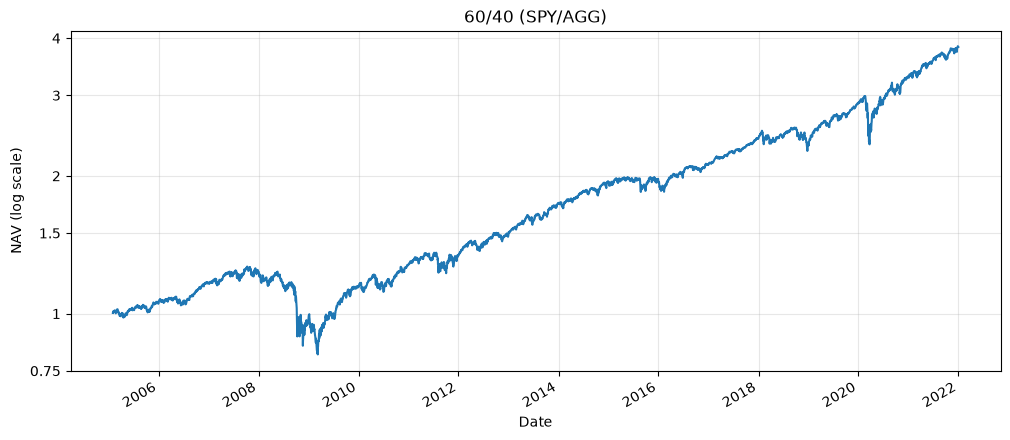

In [65]:
# we now plot the chart with the log growth of the NAV for the last sanity check

fig, ax = plt.subplots(figsize=(12,5))

NAV_6040.plot(ax=ax, logy = True, x_compat=True)
ax.set_title("60/40 (SPY/AGG)")
ax.set_ylabel("NAV (log scale)")
ticks = [0.75, 1, 1.5, 2, 3, 4] 
ax.set_yticks(ticks, labels=[str(t) for t in ticks])
ax.minorticks_off()
ax.grid(True, alpha=0.3)
plt.show()

## Equal Weights allocator

In [66]:
# load the data

close_ew = pd.read_parquet(PROCESSED / "close.parquet")
open_ew = pd.read_parquet(PROCESSED / "open.parquet")
returns_ew = pd.read_parquet(PROCESSED / "returns.parquet")
eligible_ew = pd.read_parquet(PROCESSED / "eligible.parquet")

In [67]:
# we need to check for the approach to the CAP variable

# we need at least 5 ETFs for the 20% cap to be respected, as each fund's weight will be determined by its volatility vis-a-vis the others

assert (eligible_ew.loc[rebal_dates].sum(axis=1).min())>5

print("At least 5 eligible ETFs at all time")

At least 5 eligible ETFs at all time


In [68]:
# build an allocator that assigns equal weight to all ETFs

# the eligibility criteria filtered at its minimum 9 ETFs so we do not need to edit CAP requirement

def equal_weights(window):
    number_eligibles = len(window.columns)
    weights = 1/number_eligibles # calculate proportional weights equally among eligibles
    return pd.Series(weights, index = window.columns)

In [69]:
result_ew = backtest_engine(
    equal_weights, close_ew, open_ew, returns_ew, eligible_ew, rebal_dates, cost_bp, 
    cap=CAP, lookback = LOOKBACK)

In [70]:
# sanity check the results

# NAV should be close to 1 on date 1
NAV_ew = result_ew["NAV"]
print (NAV_ew.iloc[0])
 
# 1st turnover should be 1
turnover_ew = result_ew["Turnover"]
print (turnover_ew.iloc[0])

# following that turnover should be small
turnover_ew.iloc[1:].describe()

1.0025559850732357
1.0


count    202.000000
mean       0.032801
std        0.033655
min        0.007992
25%        0.017205
50%        0.022247
75%        0.032594
max        0.250000
dtype: float64

In [71]:
performance_ew = performance_calculator(NAV_ew, rf_daily)
print(performance_ew)

# the numbers i see make sense

ann_return      0.057396
ann_vol         0.100348
sharpe          0.492381
max_drawdown   -0.337178
dtype: float64


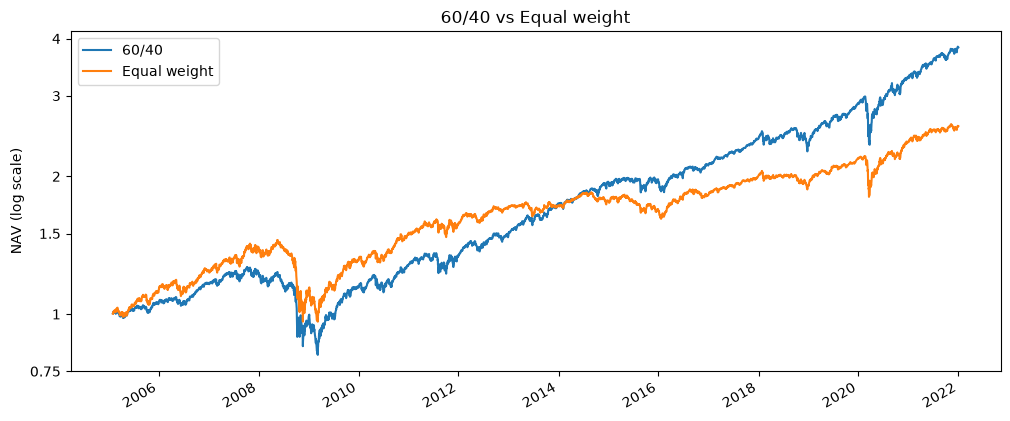

In [72]:
# let's compare the two NAVs

allocators_nav = pd.DataFrame({"60/40": NAV_6040, "Equal weight": NAV_ew})

ticks = [0.75, 1, 1.5, 2, 3, 4]
ax = allocators_nav.plot(logy=True, figsize=(12, 5), title="60/40 vs Equal weight")
ax.set_yticks(ticks, labels=[str(t) for t in ticks])
ax.minorticks_off()
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
plt.show()

In [73]:
# and their performance

allocators_performance = pd.DataFrame({"60/40": performance_6040, "Equal weight": performance_ew})
print(allocators_performance)

                 60/40  Equal weight
ann_return    0.082404      0.057396
ann_vol       0.114335      0.100348
sharpe        0.649639      0.492381
max_drawdown -0.356924     -0.337178


#### Results: 60/40 vs equal weight
Over 2005-2021, equal weight (Sharpe 0.49) trailed 60/40 (Sharpe 0.65). The gap is
regime-dependent: equal weight led until late 2013, early 2014 during the commodity and EM boom,
while 60/40 pulled ahead from 2014 as commodities fell, the dollar strengthened and
US large-cap equities outperformed most other exposures in the universe.

## Risk-Rdjusted Allocator

In [74]:
# build an allocator that assigns ETFs weights based on their standard deviation

# the eligibility criteria filtered at its minimum 9 ETFs so we do not need to edit CAP requirement

def risk_weightet(window):
    risk_score = 1 / window.std()
    weights = risk_score / risk_score.sum()
    return pd.Series(weights, index = window.columns)

In [75]:
result_rw = backtest_engine(
    risk_weightet, close_ew, open_ew, returns_ew, eligible_ew, rebal_dates, cost_bp, 
    cap=CAP, lookback = LOOKBACK)

In [76]:
# sanity check the results

# NAV should be close to 1 on date 1
NAV_rw = result_rw["NAV"]
print (NAV_rw.iloc[0])
 
# 1st turnover should be 1
turnover_rw = result_rw["Turnover"]
print (turnover_rw.iloc[0])

# following that turnover should be small
turnover_rw.iloc[1:].describe()

1.0013365089649722
1.0


count    202.000000
mean       0.029793
std        0.034992
min        0.006525
25%        0.014972
50%        0.019623
75%        0.029101
max        0.282766
dtype: float64

In [77]:
performance_rw = performance_calculator(NAV_rw, rf_daily)
print(performance_rw)

# the numbers i see make sense

ann_return      0.041755
ann_vol         0.052478
sharpe          0.587724
max_drawdown   -0.194149
dtype: float64


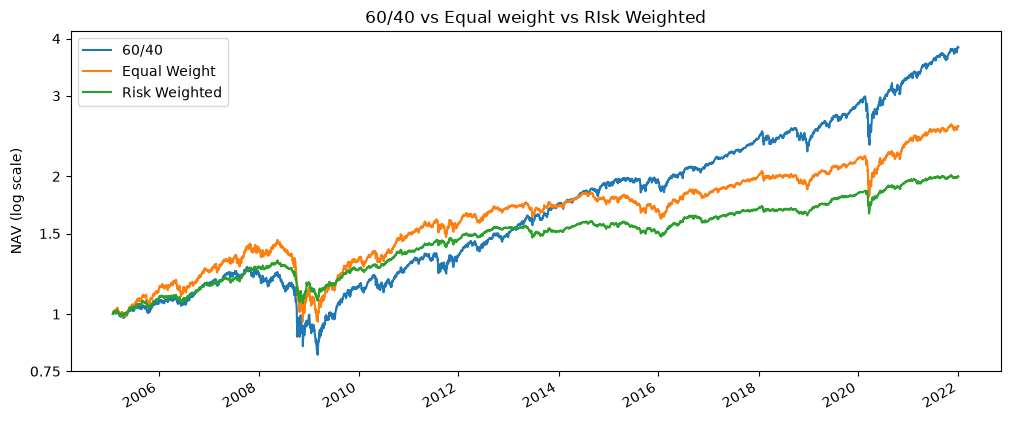

In [78]:
# let's compare the three NAVs

allocators_nav = pd.DataFrame({"60/40": NAV_6040, "Equal Weight": NAV_ew, "Risk Weighted" : NAV_rw})

ticks = [0.75, 1, 1.5, 2, 3, 4]
ax = allocators_nav.plot(logy=True, figsize=(12, 5), title="60/40 vs Equal weight vs RIsk Weighted")
ax.set_yticks(ticks, labels=[str(t) for t in ticks])
ax.minorticks_off()
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
plt.show()

In [79]:
# and their performance

allocators_performance = pd.DataFrame({"60/40": performance_6040, "Equal Weight": performance_ew,"Risk Weighted" : performance_rw})
print(allocators_performance)

                 60/40  Equal Weight  Risk Weighted
ann_return    0.082404      0.057396       0.041755
ann_vol       0.114335      0.100348       0.052478
sharpe        0.649639      0.492381       0.587724
max_drawdown -0.356924     -0.337178      -0.194149


#### Final Results

As per Sharpe:
60/40 > Risk Weighted > Equal Weight

Including risk in the determination of weights did add value in the form of reduced volatility and lower drawdown compared to the other simple allocators


A note of reference to the book is that the use of normal Sharpe can lead to misleading results
- Using the approximation for standard error of ((1 + SR²/2) / years)^(1/2) leads to an uncertainty factor of about 0.25
- The differences in the Sharpe ratios are well within this range
- This is why de Prado recommends the use of Deflated Sharpe Ratio (DSR); testing many strategies and picking the best inflates standard SR

## Data Storing

Data Results

In [88]:
# creates a df with all series
NAVs = {"sixty_forty": NAV_6040, "equal_weights": NAV_ew, "risk_weighted": NAV_rw}

# iterates over each series and 
for name, nav in NAVs.items():
    strat_returns = nav.pct_change(fill_method=None).dropna().to_frame(name) # takes % change, removes first empty entry and converts to a df
    path = BACKTEST / f"{name}.parquet" # creates path based on name of the series in the NAVs df
    if not path.exists():
        strat_returns.to_parquet(path)
    assert pd.read_parquet(path).equals(strat_returns), f"{name} did not save correctly" # double checks if all is saved correctly

print("all backtest returns saved and checked")

all backtest returns saved and checked


Data Logs

In [87]:
# to log the data, i create three separate dictionaries and the I combine them into a dataframe

row_6040 = {"date": "2026-10-28", "name": "sixty_forty", "allocator": "sixty_forty",
            "settings": "cap=None, lookback=1", "role": "benchmark",
            "ann_return": performance_6040["ann_return"], 
            "sharpe": performance_6040["sharpe"], 
            "turnover" : turnover_6040.mean(), 
            "max_drawdown" : performance_6040["max_drawdown"],
            "returns_file": "results/backtests/sixty_forty.parquet"}

row_ew = {"date": "2026-10-28", "name": "equal_weights", "allocator": "equal_weights",
            "settings": "cap=0.2, lookback=504", "role": "benchmark",
            "ann_return": performance_ew["ann_return"],
            "sharpe": performance_ew["sharpe"], 
            "turnover" : turnover_ew.mean(), 
            "max_drawdown" : performance_ew["max_drawdown"],
            "returns_file": "results/backtests/equal_weights.parquet"}

row_rw = {"date": "2026-10-28", "name": "risk_weighted", "allocator": "risk_weighted",
            "settings": "cap=0.2, lookback=504", "role": "diagnostic",
            "ann_return": performance_rw["ann_return"],
            "sharpe": performance_rw["sharpe"], 
            "turnover" : turnover_ew.mean(), 
            "max_drawdown" : performance_ew["max_drawdown"],
            "returns_file": "results/backtests/risk_weighted.parquet"}

logs = pd.DataFrame([row_6040, row_ew, row_rw])

In [89]:
logs

,date,name,allocator,settings,role,ann_return,sharpe,turnover,max_drawdown,returns_file
0,2026-10-28,sixty_forty,sixty_forty,"cap=None, lookback=1",benchmark,0.082404,0.649639,0.021518,-0.356924,results/backtests/sixty_forty.parquet
1,2026-10-28,equal_weights,equal_weights,"cap=0.2, lookback=504",benchmark,0.057396,0.492381,0.037566,-0.337178,results/backtests/equal_weights.parquet
2,2026-10-28,risk_weighted,risk_weighted,"cap=0.2, lookback=504",diagnostic,0.041755,0.587724,0.037566,-0.337178,results/backtests/risk_weighted.parquet


In [91]:
# Add new strategy runs to the trials log, replacing older rows with the same name

def update_trials_log(new_rows, path=TRIALS_LOG):
    # load the existing log, or start empty if the file is missing or empty
    if path.exists() and path.stat().st_size > 0:
        log = pd.read_csv(path)
    else:
        log = pd.DataFrame()

    # remove old rows for the strategies being written now
    if not log.empty:
        log = log[~log["name"].isin(new_rows["name"])] # new log is old log without the rows that appear in new_row

    # add the new rows below the remaining ones
    log = pd.concat([log, new_rows], ignore_index=True)

    # save the whole log, overwriting the file
    log.to_csv(path, index=False)
    return log

In [92]:
update_trials_log (logs)
pd.read_csv(TRIALS_LOG)

,date,name,allocator,settings,role,ann_return,sharpe,turnover,max_drawdown,returns_file
0,2026-10-28,sixty_forty,sixty_forty,"cap=None, lookback=1",benchmark,0.082404,0.649639,0.021518,-0.356924,results/backtests/sixty_forty.parquet
1,2026-10-28,equal_weights,equal_weights,"cap=0.2, lookback=504",benchmark,0.057396,0.492381,0.037566,-0.337178,results/backtests/equal_weights.parquet
2,2026-10-28,risk_weighted,risk_weighted,"cap=0.2, lookback=504",diagnostic,0.041755,0.587724,0.037566,-0.337178,results/backtests/risk_weighted.parquet
